In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# 1. 데이터 불러오기
df = pd.read_csv("diabetes.csv")

# Glucose가 0인 행은 결측치이므로 제거
df = df[df["Glucose"] != 0]

print(df.head())
print(df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(763, 9)


In [ ]:
# 2. 입력 / 정답 분리 (타깃: Glucose)
X = df.drop("Glucose", axis=1)
y = df["Glucose"]

## 딥러닝 입력을 위해 Numpy로 변환

In [ ]:
X = X.values
y = y.values

print(X.shape, y.shape)

(763, 8) (763,)


In [ ]:
# 3. 학습 / 테스트 데이터 분리 (회귀이므로 stratify 사용 안 함)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 4. 데이터 정규화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# 5. 모델 생성
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(32, activation="relu", input_shape=(8,)))  # Feature number = 8
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(1))                                       # 출력 뉴런 1, 활성화 함수 없음(linear)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# 6. 모델 설정
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [ ]:
# 7. 모델 구조 출력
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 8. 모델 학습
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 649.6238 - mae: 20.2284 - val_loss: 619.3480 - val_mae: 19.4395
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 647.9350 - mae: 20.2529 - val_loss: 621.8390 - val_mae: 19.5055
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 645.3861 - mae: 20.1948 - val_loss: 616.4205 - val_mae: 19.3836
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 643.1818 - mae: 20.1476 - val_loss: 614.3471 - val_mae: 19.3725
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 641.3575 - mae: 20.1183 - val_loss: 613.2137 - val_mae: 19.3703
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 638.8206 - mae: 20.0696 - val_loss: 607.4384 - val_mae: 19.2362
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 636.7302 - mae: 20.0235 - val_loss: 605.4816 - val_mae: 19.2027
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 636.2330 - mae: 19.9868 - val_loss: 600.8812 - val_mae: 19.0812
Epoch 9/30
16/16 

In [ ]:
# 9. 테스트 데이터 예측
y_pred = model.predict(X_test).flatten()

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [ ]:
# 10. 성능 평가
mse = mean_squared_error(y_test, y_pred)
print("MSE  =", mse)
print("RMSE =", np.sqrt(mse))
print("MAE  =", mean_absolute_error(y_test, y_pred))
print("R2   =", r2_score(y_test, y_pred))

MSE  = 15994.0029296875
RMSE = 126.46739868316854
MAE  = 122.69805908203125
R2   = -16.310073852539062


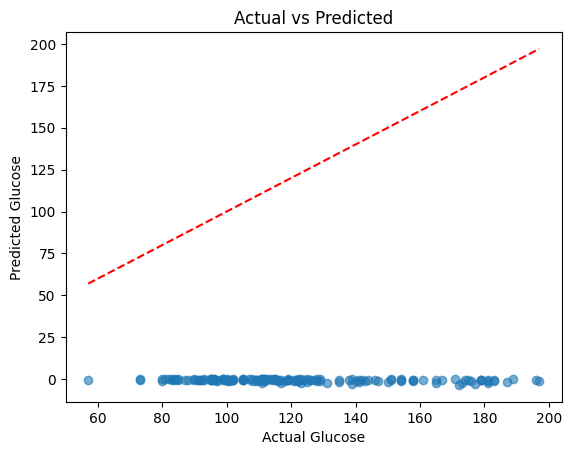

In [ ]:
# 11. 실제값 vs 예측값 시각화
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Glucose")
plt.ylabel("Predicted Glucose")
plt.title("Actual vs Predicted")
plt.show()